# 1. Carga y descripción inicial de los datos

El conjunto de datos utilizado contiene información sobre los nacidos vivos registrados en la República Argentina entre los años 2005 y 2022.

En esta primera etapa se carga el archivo y se realiza una inspección inicial para conocer sus dimensiones, las variables disponibles y la estructura de los registros. También se observan las primeras filas para familiarizarse con el formato y el contenido de los datos.

Esta revisión se realiza antes de aplicar filtros, eliminar registros o modificar variables. De esta manera, se obtiene una primera aproximación a la información disponible y se establece un punto de partida para el análisis exploratorio y la posterior preparación de los datos para el modelado.

In [1]:
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
)
from sklearn.model_selection import (
    GridSearchCV,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


In [2]:
ruta = "../data/raw/nacidos-vivos-registrados-en-la-republica-argentina-entre-los-anos-2005-2022.csv"

df = pd.read_csv(ruta, low_memory=False)

In [3]:
# Dimensiones
print(f"Cantidad de filas: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")

Cantidad de filas: 546,963
Cantidad de columnas: 12


In [4]:
print(df.columns.tolist())

['anio', 'jurisdiccion_de_residencia_id', 'jurisdicion_residencia_nombre', 'edad_madre_grupo', 'instruccion_madre', 'tipo_de_parto_id', 'tipo_de_parto_nombre', 'semana_gestacion', 'intervalo_peso_al_nacer', 'sexo_id', 'Sexo', 'nacimientos_cantidad']


In [5]:
display(df.head())

,anio,jurisdiccion_de_residencia_id,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_id,tipo_de_parto_nombre,semana_gestacion,intervalo_peso_al_nacer,sexo_id,Sexo,nacimientos_cantidad
0,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,4.28 a 31,2.500 a 999,1,masculino,2
1,2022,6,Buenos Aires,3.20 a 24,4.Secundaria/Polimodal Incompleta,1.0,Simple,1.Menos de 22,2.500 a 999,1,masculino,1
2,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,3.24 a 27,2.500 a 999,1,masculino,2
3,2022,6,Buenos Aires,3.20 a 24,4.Secundaria/Polimodal Incompleta,1.0,Simple,3.24 a 27,4.1500 a 1999,1,masculino,2
4,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,2.22 a 23,2.500 a 999,1,masculino,1


# 2. Análisis exploratorio de datos (EDA)

En esta etapa se analiza la estructura, la calidad y las características generales del conjunto de datos antes de realizar modificaciones.

El análisis exploratorio permite identificar valores faltantes, categorías sin especificar y posibles inconsistencias en las variables. Además, permite conocer mejor la información disponible y detectar aspectos que pueden ser relevantes para el problema de clasificación del bajo peso al nacer.

A partir de los resultados obtenidos, se evaluarán las decisiones necesarias para preparar los datos antes del entrenamiento de los modelos.

In [6]:
# Cantidad de valores faltantes por variable
faltantes = df.isna().sum()

# Porcentaje de valores faltantes por variable
porcentaje_faltantes = (df.isna().mean() * 100).round(2)

resumen_faltantes = pd.DataFrame({
    "valores_faltantes": faltantes,
    "porcentaje_faltantes": porcentaje_faltantes
})

display(resumen_faltantes.sort_values(
    by="porcentaje_faltantes",
    ascending=False
))

,valores_faltantes,porcentaje_faltantes
jurisdicion_residencia_nombre,2755,0.5
anio,0,0.0
jurisdiccion_de_residencia_id,0,0.0
edad_madre_grupo,0,0.0
instruccion_madre,0,0.0
tipo_de_parto_id,1,0.0
tipo_de_parto_nombre,1,0.0
semana_gestacion,0,0.0
intervalo_peso_al_nacer,0,0.0
sexo_id,0,0.0


In [7]:
# Seleccionar registros sin jurisdicción informada
sin_jurisdiccion = df[df["jurisdicion_residencia_nombre"].isna()]

print("Cantidad de registros:", len(sin_jurisdiccion))

display(sin_jurisdiccion.head(10))

Cantidad de registros: 2755


,anio,jurisdiccion_de_residencia_id,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_id,tipo_de_parto_nombre,semana_gestacion,intervalo_peso_al_nacer,sexo_id,Sexo,nacimientos_cantidad
5594,2011,98,NaN,4.25 a 29,3.Primaria/C. EGB Completa,1.0,Simple,5.32 a 36,7.3000 a 3499,1,masculino,1
5595,2011,98,NaN,4.25 a 29,3.Primaria/C. EGB Completa,1.0,Simple,6.37 a 41,7.3000 a 3499,1,masculino,1
6901,2013,98,NaN,1.Menor de 15,2.Primaria/C. EGB Incompleta,1.0,Simple,6.37 a 41,7.3000 a 3499,1,masculino,1
6902,2013,98,NaN,1.Menor de 15,3.Primaria/C. EGB Completa,1.0,Simple,6.37 a 41,5.2000 a 2499,1,masculino,1
6903,2013,98,NaN,1.Menor de 15,3.Primaria/C. EGB Completa,1.0,Simple,6.37 a 41,7.3000 a 3499,1,masculino,1
6904,2013,98,NaN,2.15 a 19,1.Sin instrucción,1.0,Simple,5.32 a 36,4.1500 a 1999,1,masculino,1
6905,2013,98,NaN,2.15 a 19,2.Primaria/C. EGB Incompleta,1.0,Simple,4.28 a 31,3.1000 a 1499,1,masculino,1
6906,2013,98,NaN,2.15 a 19,2.Primaria/C. EGB Incompleta,1.0,Simple,5.32 a 36,7.3000 a 3499,1,masculino,1
6907,2013,98,NaN,2.15 a 19,2.Primaria/C. EGB Incompleta,1.0,Simple,6.37 a 41,5.2000 a 2499,1,masculino,2
6908,2013,98,NaN,2.15 a 19,2.Primaria/C. EGB Incompleta,1.0,Simple,6.37 a 41,6.2500 a 2999,1,masculino,1


In [8]:
df.groupby(
    "jurisdiccion_de_residencia_id",
    dropna=False
).agg(
    registros=("jurisdicion_residencia_nombre", "size"),
    nombres_faltantes=("jurisdicion_residencia_nombre",
                      lambda x: x.isna().sum()),
    nacimientos=("nacimientos_cantidad", "sum")
).sort_values(
    "nombres_faltantes",
    ascending=False
).head(10)

,registros,nombres_faltantes,nacimientos
jurisdiccion_de_residencia_id,,,
98,2755,2755,4676
2,31100,0,708770
10,13916,0,115060
14,32007,0,973406
18,27307,0,344864
22,28438,0,393820
26,13461,0,160475
30,22958,0,376712
34,17362,0,203134


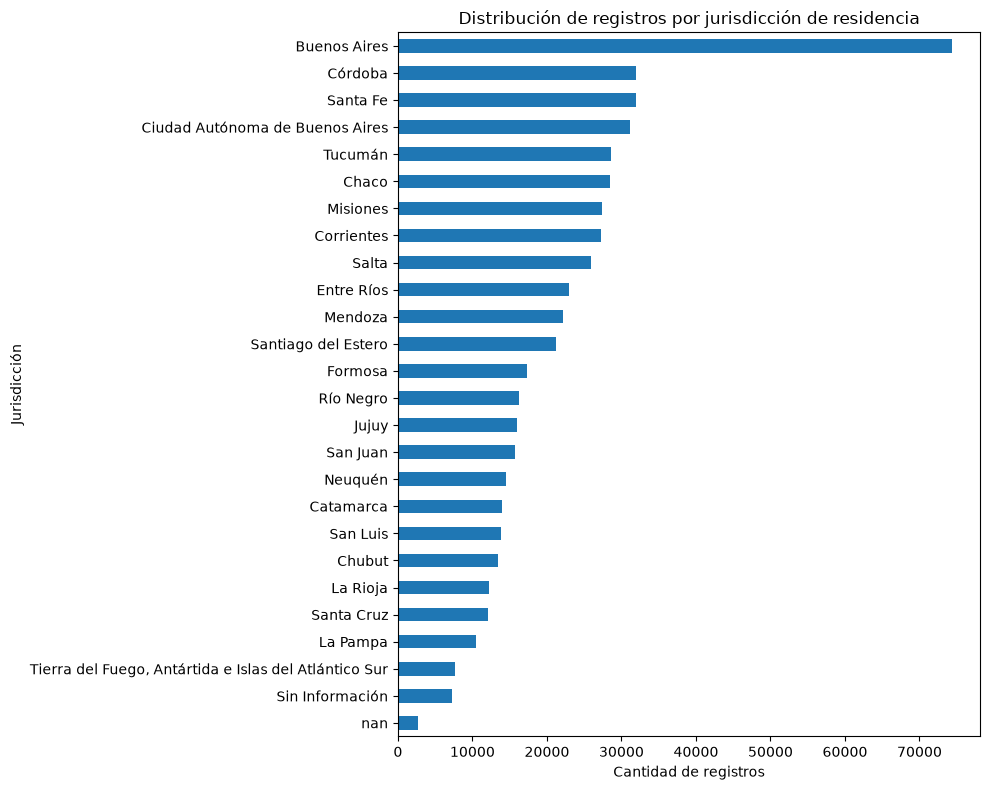

In [9]:
import matplotlib.pyplot as plt

frecuencias = df["jurisdicion_residencia_nombre"].value_counts(
    dropna=False
).sort_values(ascending=True)

frecuencias.plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Distribución de registros por jurisdicción de residencia")
plt.xlabel("Cantidad de registros")
plt.ylabel("Jurisdicción")
plt.tight_layout()
plt.show()

**Interpretación:** La variable de jurisdicción de residencia presenta 7.199 registros clasificados como «Sin Información» y 2.755 registros con valores nulos (`NaN`). Ambos casos indican que no se dispone de una jurisdicción nominal identificada.

Como decisión preliminar, se propone unificar los valores nulos con la categoría «Sin Información», evitando crear una categoría adicional. Esta transformación se realizará durante la preparación de los datos, una vez finalizado el análisis exploratorio.

In [10]:
df_eda = df.copy()

In [11]:
df_eda["jurisdicion_residencia_nombre"] = (
    df_eda["jurisdicion_residencia_nombre"]
    .fillna("Sin Información")
)

In [12]:
print(
    df_eda["jurisdicion_residencia_nombre"]
    .value_counts(dropna=False)
    .tail()
)

print(
    "\nValores faltantes restantes:",
    df_eda["jurisdicion_residencia_nombre"].isna().sum()
)

jurisdicion_residencia_nombre
La Rioja                                                 12215
Santa Cruz                                               12085
La Pampa                                                 10480
Sin Información                                           9954
Tierra del Fuego, Antártida e Islas del Atlántico Sur     7670
Name: count, dtype: int64

Valores faltantes restantes: 0


## 2.1 Análisis inicial de valores faltantes

El análisis de valores faltantes muestra que la variable `jurisdicion_residencia_nombre` contiene 2.755 registros sin un nombre de jurisdicción informado. Al revisar estos registros, se observa que todos presentan el identificador de jurisdicción 98.

Además, la variable ya contiene una categoría denominada «Sin Información», que representa casos en los que no se dispone de una jurisdicción nominal identificada.

Por este motivo, se propone unificar los valores nulos con dicha categoría durante la preparación de los datos. Esta decisión permite conservar los registros y evitar la incorporación de una categoría adicional que represente la misma falta de información.

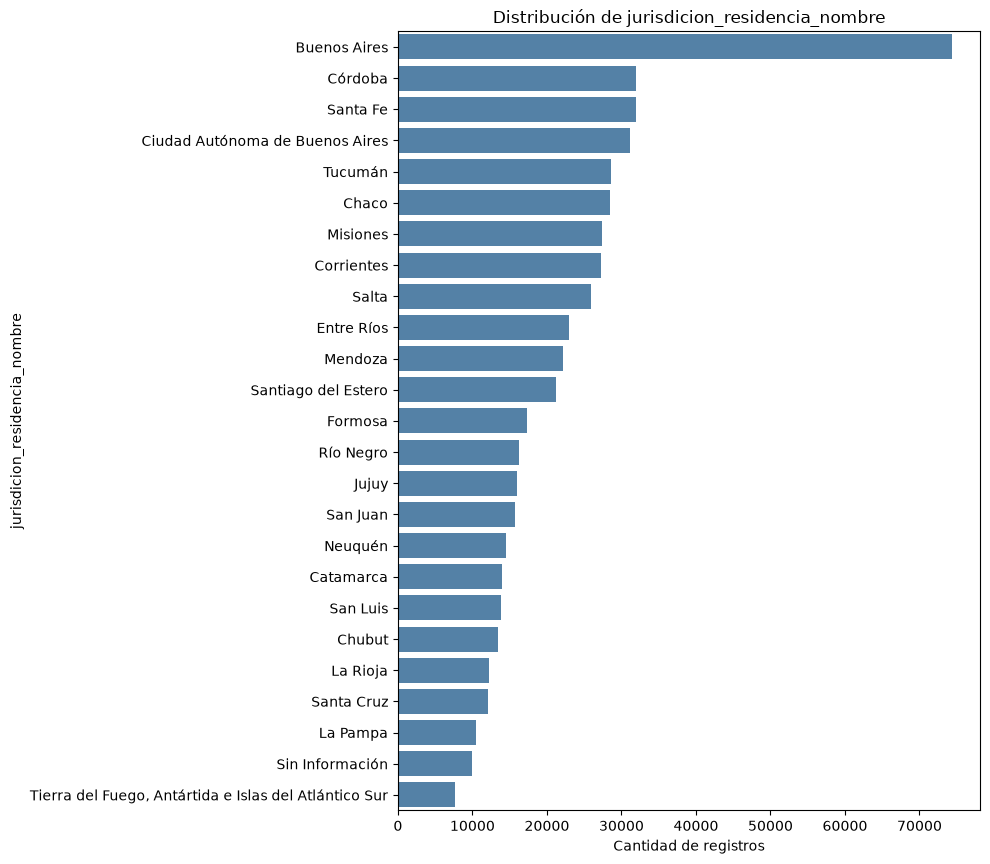

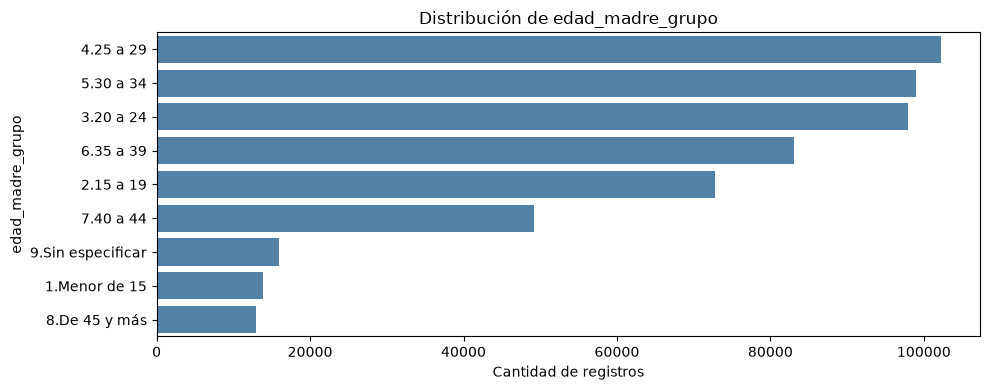

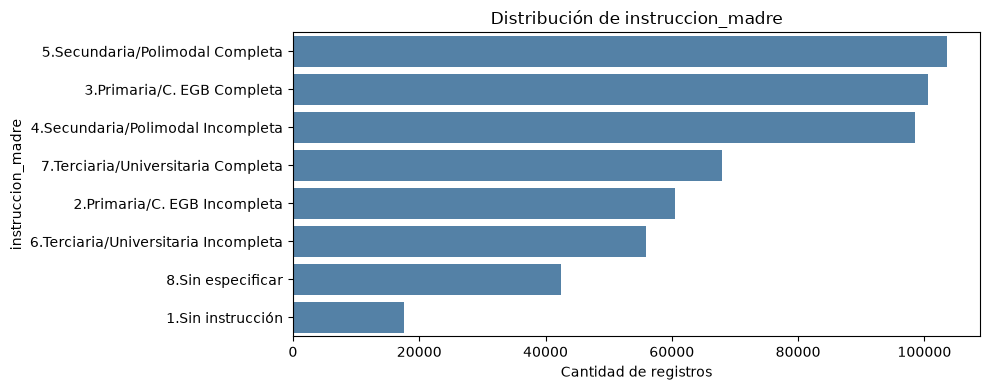

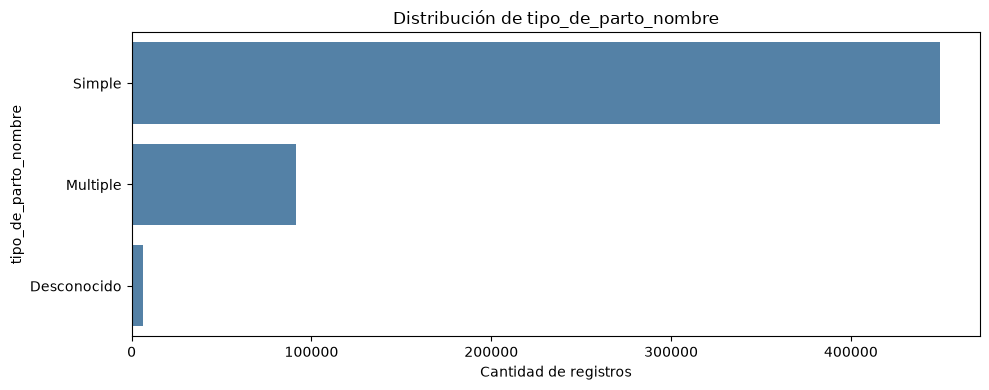

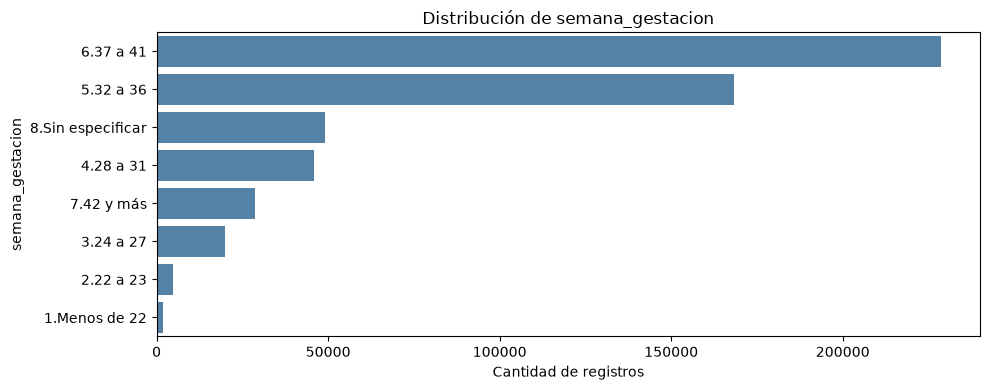

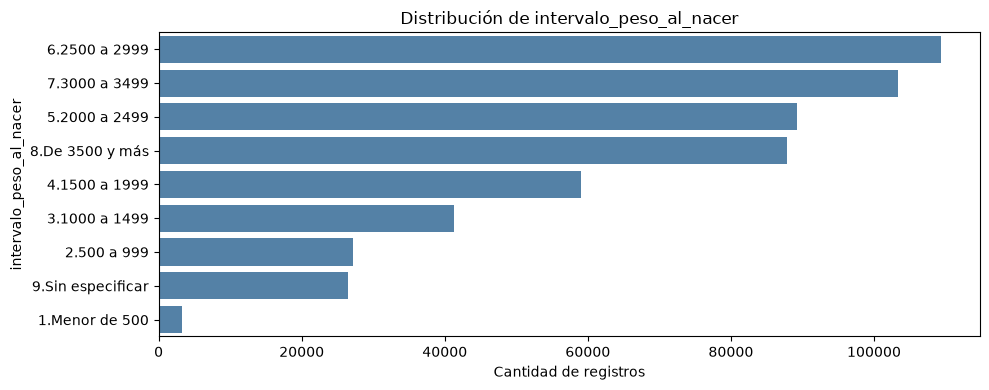

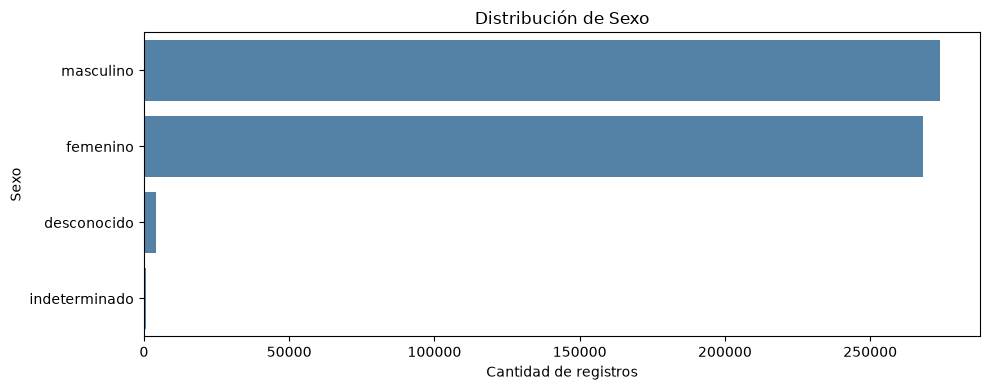

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

variables_categoricas = [
    "jurisdicion_residencia_nombre",
    "edad_madre_grupo",
    "instruccion_madre",
    "tipo_de_parto_nombre",
    "semana_gestacion",
    "intervalo_peso_al_nacer",
    "Sexo"
]

for variable in variables_categoricas:
    frecuencias = df_eda[variable].value_counts(dropna=False)

    plt.figure(figsize=(10, max(4, len(frecuencias) * 0.35)))
    sns.barplot(
        x=frecuencias.values,
        y=frecuencias.index.astype(str),
        color="steelblue"
    )

    plt.title(f"Distribución de {variable}")
    plt.xlabel("Cantidad de registros")
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()

## 2.2 Tratamiento de categorías y valores sin especificar

A partir del análisis exploratorio, se identificaron dos situaciones que requieren un tratamiento específico antes de continuar con el análisis.

**Unificación de las categorías de sexo**

La variable `Sexo` presenta las categorías *Desconocido* e *Indeterminado*. Para simplificar su representación, ambas se unifican bajo la categoría *Desconocido*. Esta transformación permite evitar la fragmentación de registros en categorías que se consideran equivalentes para el análisis, sin eliminar información ni modificar la cantidad de nacimientos representada.

**Exclusión de registros con peso al nacer sin especificar**

En la variable `intervalo_peso_al_nacer` se identificó la categoría `9.Sin especificar`. Estos registros se excluyen del conjunto de trabajo, ya que no cuentan con información suficiente para determinar el intervalo de peso al nacer y, por lo tanto, no permiten establecer de manera confiable la variable objetivo relacionada con el bajo peso al nacer.

La exclusión se realiza sobre la copia de trabajo `df_eda`, conservando intacto el conjunto de datos original `df`. Esta decisión implica que los nacimientos representados por los registros eliminados no formarán parte del análisis posterior, por lo que su cantidad debe quedar documentada.

Las demás categorías asociadas a información desconocida o no identificada se conservan, ya que corresponden a categorías presentes en los datos y su tratamiento se evaluará según la naturaleza de cada variable.

In [14]:
# Unificar las categorías de sexo desconocido o indeterminado
sexo_normalizado = df_eda["Sexo"].astype("string").str.strip()

mascara_indeterminado = (
    sexo_normalizado.str.casefold() == "indeterminado"
)

df_eda.loc[mascara_indeterminado, "Sexo"] = "Desconocido"

# Verificar las categorías resultantes
print(df_eda["Sexo"].value_counts(dropna=False))

Sexo
masculino      274103
femenino       268035
desconocido      4001
Desconocido       824
Name: count, dtype: int64


In [15]:
mascara_peso_sin_especificar = (
    df_eda["intervalo_peso_al_nacer"] == "9.Sin especificar"
)

registros_a_eliminar = mascara_peso_sin_especificar.sum()

nacimientos_a_eliminar = df_eda.loc[
    mascara_peso_sin_especificar, "nacimientos_cantidad"
].sum()

print("Registros a eliminar:", registros_a_eliminar)
print("Nacimientos representados:", nacimientos_a_eliminar)

Registros a eliminar: 26432
Nacimientos representados: 145857


In [16]:
df_eda = df_eda.loc[
    ~mascara_peso_sin_especificar
].copy()

In [17]:
print(
    "Registros con peso sin especificar:",
    (df_eda["intervalo_peso_al_nacer"] == "9.Sin especificar").sum()
)

Registros con peso sin especificar: 0


# 3. Creación de la variable objetivo

El objetivo del proyecto es desarrollar modelos de aprendizaje automático capaces de predecir si un nacimiento presenta bajo peso al nacer. Para ello, se crea una variable objetivo binaria a partir de la variable `intervalo_peso_al_nacer`.

Se considera bajo peso al nacer un peso inferior a 2.500 gramos. Por lo tanto, se asigna el valor **1** a los nacimientos pertenecientes a categorías inferiores a dicho umbral y el valor **0** a los nacimientos con un peso igual o superior a 2.500 gramos.

Los registros cuya categoría de peso era `9.Sin especificar` fueron excluidos durante la limpieza, ya que no permiten determinar la clase objetivo. La variable original se conserva para mantener la referencia a los intervalos de peso, aunque no deberá utilizarse como variable predictora, dado que contiene directamente la información a partir de la cual se construye el objetivo y produciría fuga de información (*data leakage*).

In [18]:
display(
    df_eda.groupby("intervalo_peso_al_nacer", dropna=False)
    ["nacimientos_cantidad"]
    .agg(
        cantidad_registros="size",
        cantidad_nacimientos="sum"
    )
    .sort_values("cantidad_nacimientos", ascending=False)
)

,cantidad_registros,cantidad_nacimientos
intervalo_peso_al_nacer,,
7.3000 a 3499,103409,4991636
8.De 3500 y más,87849,4243658
6.2500 a 2999,109349,2178250
5.2000 a 2499,89207,577126
4.1500 a 1999,59026,182556
3.1000 a 1499,41334,87406
2.500 a 999,27115,47198
1.Menor de 500,3242,3630


In [19]:
print("Cantidad de registros:", len(df_eda))
print("Nacimientos representados:", df_eda["nacimientos_cantidad"].sum())
print("Valores nulos:", df_eda["nacimientos_cantidad"].isna().sum())
print("Valores iguales a cero:", (df_eda["nacimientos_cantidad"] == 0).sum())
print("Valores negativos:", (df_eda["nacimientos_cantidad"] < 0).sum())

Cantidad de registros: 520531
Nacimientos representados: 12311460
Valores nulos: 0
Valores iguales a cero: 0
Valores negativos: 0


In [20]:
# Crear la variable binaria
df_eda["bajo_peso"] = (
    df_eda["intervalo_peso_al_nacer"].isin([
        "1.Menor de 500",
        "2.500 a 999",
        "3.1000 a 1499",
        "4.1500 a 1999",
        "5.2000 a 2499"
    ])
).astype(int)

In [21]:
# Validar la variable objetivo
resumen_objetivo = (
    df_eda.groupby("bajo_peso")["nacimientos_cantidad"]
    .agg(
        cantidad_registros="size",
        cantidad_nacimientos="sum"
    )
)

resumen_objetivo.index = resumen_objetivo.index.map({
    0: "Peso normal (>= 2500 g)",
    1: "Bajo peso (< 2500 g)"
})

display(resumen_objetivo)

,cantidad_registros,cantidad_nacimientos
bajo_peso,,
Peso normal (>= 2500 g),300607,11413544
Bajo peso (< 2500 g),219924,897916


In [22]:
# Verifiquemos que la clasificación no haya dejado registros sin asignar
print("Valores nulos en bajo_peso:", df_eda["bajo_peso"].isna().sum())
print("Clases presentes:", sorted(df_eda["bajo_peso"].unique()))

Valores nulos en bajo_peso: 0
Clases presentes: [np.int64(0), np.int64(1)]


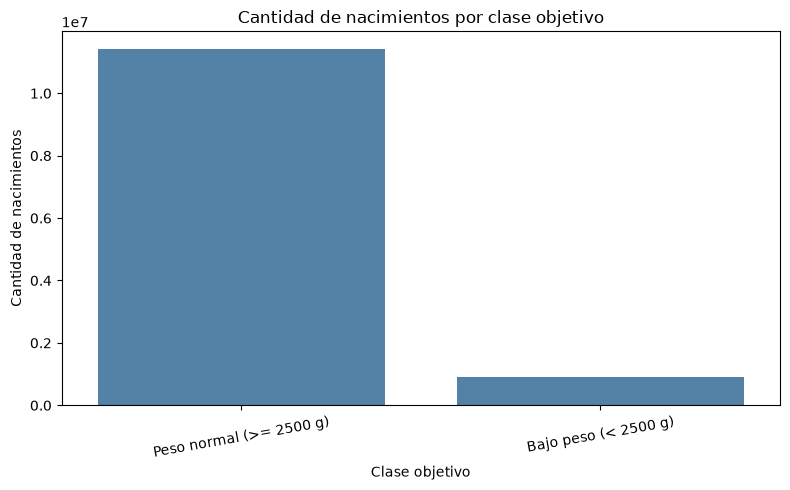

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comprobar el balance de clases
nacimientos_por_clase = (
    df_eda.groupby("bajo_peso")["nacimientos_cantidad"]
    .sum()
    .rename(index={
        0: "Peso normal (>= 2500 g)",
        1: "Bajo peso (< 2500 g)"
    })
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=nacimientos_por_clase.index,
    y=nacimientos_por_clase.values,
    color="steelblue"
)

plt.title("Cantidad de nacimientos por clase objetivo")
plt.xlabel("Clase objetivo")
plt.ylabel("Cantidad de nacimientos")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Desbalance de clases

Al analizar la variable objetivo `bajo_peso`, se observa que la distribución depende de la unidad que se considere.

Como el dataset contiene registros agregados que representan diferentes cantidades de nacimientos, es necesario distinguir entre la cantidad de filas y la cantidad de nacimientos representados.

Según la suma de `nacimientos_cantidad`, los nacimientos con bajo peso (menos de 2.500 gramos) representan aproximadamente el 7,3 % de los nacimientos incluidos después de la limpieza. Por lo tanto, constituyen la clase minoritaria cuando se considera la cantidad real de nacimientos.

Para el modelado se conservará la variable `nacimientos_cantidad` como ponderador, de modo que los registros contribuyan a los cálculos de acuerdo con la cantidad de nacimientos que representan.

La división entre entrenamiento y prueba se realizará mediante muestreo estratificado según la variable objetivo. La distribución de los nacimientos representados se verificará por separado, ya que la estratificación por filas no garantiza por sí sola que las cantidades ponderadas mantengan exactamente la misma proporción.

Durante la evaluación se priorizarán métricas como *recall*, F1-score y la matriz de confusión, calculadas teniendo en cuenta los ponderadores cuando corresponda.

# 4. Preparación de las variables para el modelado

Una vez definida la variable objetivo y separados los registros cuyo peso al nacer no se encuentra especificado, se prepara el conjunto de datos que se utilizará para entrenar los modelos de clasificación.

En esta etapa se seleccionan las variables predictoras y se determinan cuáles deben excluirse del modelado. También se conserva la información necesaria para que cada registro contribuya a los resultados de acuerdo con la cantidad de nacimientos que representa.

Se utilizan como variables predictoras seis características categóricas:

- Jurisdicción de residencia.
- Grupo de edad materna.
- Nivel de instrucción materna.
- Tipo de parto.
- Semana de gestación.
- Sexo.

Se excluyen de las variables predictoras:

- `intervalo_peso_al_nacer`, porque se utiliza para construir la variable objetivo `bajo_peso`. Incorporarla como predictor permitiría al modelo acceder directamente a la información que se busca clasificar, generando fuga de información (*data leakage*).
- `nacimientos_cantidad`, porque representa la cantidad de nacimientos asociados a cada registro y se utiliza como ponderador, no como característica predictora.
- Los identificadores numéricos y la variable `anio`, que no forman parte de esta primera especificación del modelo.

Por último, los valores nulos reales de las variables categóricas se completan con la etiqueta `"Desconocido"`. Las categorías explícitas como `"Sin especificar"` se conservan, ya que representan una condición registrada en los datos y no necesariamente un valor nulo.

Estas decisiones permiten definir un conjunto de variables coherente con el objetivo de clasificación y preparar los datos para las siguientes etapas de preprocesamiento y entrenamiento.

In [24]:
sklearn.set_config(enable_metadata_routing=True)

In [25]:
variables_predictoras = [
    "jurisdicion_residencia_nombre",
    "edad_madre_grupo",
    "instruccion_madre",
    "tipo_de_parto_nombre",
    "semana_gestacion",
    "Sexo"
]

# Completar valores nulos de las variables predictoras
df_eda[variables_predictoras] = (
    df_eda[variables_predictoras]
    .fillna("Desconocido")
)

# Separar variables predictoras, objetivo y ponderadores
X = df_eda[variables_predictoras].copy()
y = df_eda["bajo_peso"].copy()
pesos = df_eda["nacimientos_cantidad"].copy()

# Verificar valores faltantes
print("Valores nulos en X:", X.isna().sum().sum())

Valores nulos en X: 0


## 5. División de los datos en entrenamiento y prueba

Para evaluar el desempeño de los modelos sobre datos que no hayan sido utilizados durante el entrenamiento, se divide el conjunto de datos en dos subconjuntos: entrenamiento y prueba.

Se utiliza una proporción del 80 % para entrenamiento y del 20 % para prueba. El conjunto de entrenamiento se emplea para ajustar los modelos y seleccionar sus hiperparámetros, mientras que el conjunto de prueba se reserva para realizar la evaluación final.

La división se realiza mediante un muestreo estratificado (`stratify`), con el objetivo de mantener una proporción similar de las clases de la variable objetivo (`bajo_peso`) en ambos subconjuntos. Esto resulta importante debido a que los nacimientos con bajo peso representan una proporción menor del total.

Además, se establece `random_state=42` para que la división pueda reproducirse en futuras ejecuciones.

Por otra parte, se conserva la variable `pesos`, construida a partir de `nacimientos_cantidad`, que indica la cantidad de nacimientos representados por cada registro. Esta variable se utilizará como ponderador durante el entrenamiento y la evaluación de los modelos, de modo que los resultados tengan en cuenta la cantidad de nacimientos representados por cada fila y no solamente el número de registros.

In [26]:
# separar entrenamiento y prueba
X_train, X_test, y_train, y_test, pesos_train, pesos_test = train_test_split(
    X,
    y,
    pesos,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [27]:
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nProporción de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nProporción de clases en prueba:")
print(y_test.value_counts(normalize=True).sort_index())

print("\nNacimientos representados en entrenamiento:", pesos_train.sum())
print("Nacimientos representados en prueba:", pesos_test.sum())

# Proporción ponderada de nacimientos con bajo peso
proporcion_bajo_peso_train = (
    pesos_train[y_train == 1].sum() / pesos_train.sum()
)

proporcion_bajo_peso_test = (
    pesos_test[y_test == 1].sum() / pesos_test.sum()
)

print(
    "Proporción ponderada de bajo peso en entrenamiento:",
    round(proporcion_bajo_peso_train * 100, 2), "%"
)

print(
    "Proporción ponderada de bajo peso en prueba:",
    round(proporcion_bajo_peso_test * 100, 2), "%"
)

Registros de entrenamiento: 416424
Registros de prueba: 104107

Proporción de clases en entrenamiento:
bajo_peso
0    0.5775
1    0.4225
Name: proportion, dtype: float64

Proporción de clases en prueba:
bajo_peso
0    0.577502
1    0.422498
Name: proportion, dtype: float64

Nacimientos representados en entrenamiento: 9903661
Nacimientos representados en prueba: 2407799
Proporción ponderada de bajo peso en entrenamiento: 7.25 %
Proporción ponderada de bajo peso en prueba: 7.49 %


> La división estratificada mantuvo prácticamente idéntica la proporción de filas de cada clase en los conjuntos de entrenamiento y prueba. Al considerar la cantidad de nacimientos representados por cada registro, la proporción de bajo peso fue del 7,25 % en entrenamiento y del 7,49 % en prueba. Esta diferencia se debe a que la estratificación se realizó sobre las etiquetas de las filas y no sobre la cantidad de nacimientos representados.

# 6. Preprocesamiento y Pipelines
Se seleccionó `One-Hot Encoding` para transformar las variables categóricas de ambos modelos. Esta técnica permite representar las categorías sin establecer relaciones numéricas artificiales entre ellas y proporciona un preprocesamiento común para la Regresión Logística y Random Forest.

Aunque la `codificación ordinal` podría ser una alternativa para las variables con categorías ordenadas, se priorizó una estrategia uniforme y reproducible, conservando las categorías sin información específica. No se presupone que esta elección sea superior en todos los casos, sino que se considera una alternativa adecuada para el problema y se centra la optimización experimental en los hiperparámetros de los modelos.

In [28]:
variables_categoricas = X_train.columns.tolist()

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        )
    ],
    remainder="drop"
)

# 7. Guardado de los conjuntos de datos para el modelado

Una vez finalizadas la exploración, la limpieza y la preparación de los datos, se guardaron los conjuntos de entrenamiento y prueba en formato CSV dentro de la carpeta `data/interim/`.

Se generaron los siguientes archivos:

- `X_train.csv` y `X_test.csv`: contienen las variables predictoras de los conjuntos de entrenamiento y prueba.
- `y_train.csv` y `y_test.csv`: contienen la variable objetivo `bajo_peso` correspondiente a cada conjunto.
- `pesos_train.csv` y `pesos_test.csv`: contienen la cantidad de nacimientos representados por cada registro, que se utilizará como ponderación durante el entrenamiento y la evaluación.

Esta separación permite conservar las variables predictoras, la variable objetivo y los pesos de forma independiente, facilitando su carga y utilización en la siguiente etapa del proyecto.

**Próxima etapa:** en el notebook `02_modelado_evaluacion.ipynb` se cargarán estos archivos para construir los pipelines de preprocesamiento y modelado, realizar la búsqueda de hiperparámetros y evaluar el desempeño de los modelos de clasificación.

In [29]:
# ============================================
# GUARDAR DATOS PARA LA SIGUIENTE ETAPA
# ============================================

from pathlib import Path

ruta_salida = Path("../data/interim")

ruta_salida.mkdir(parents=True, exist_ok=True)

X_train.to_csv(ruta_salida / "X_train.csv", index=False)
X_test.to_csv(ruta_salida / "X_test.csv", index=False)

y_train.to_frame(name="bajo_peso").to_csv(
    ruta_salida / "y_train.csv", index=False
)
y_test.to_frame(name="bajo_peso").to_csv(
    ruta_salida / "y_test.csv", index=False
)

pesos_train.to_frame(name="nacimientos_cantidad").to_csv(
    ruta_salida / "pesos_train.csv", index=False
)
pesos_test.to_frame(name="nacimientos_cantidad").to_csv(
    ruta_salida / "pesos_test.csv", index=False
)

print("Conjuntos de entrenamiento y prueba guardados correctamente.")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

Conjuntos de entrenamiento y prueba guardados correctamente.
X_train: (416424, 6)
X_test: (104107, 6)
